<a href="https://colab.research.google.com/github/MarcoLuw/QoE-MOS-Prediction/blob/main/model_training/random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature description

| # | Column | Category | Meaning / Practical Use | Values / Details from README |
|---|--------|----------|--------------------------|------------------------------|
| 1 | id | Identifier | Unique identifier of the sample (one video-viewing test record). | Not further defined in README |
| 2 | user_id | Identifier | Identifier of the tester who performed the session; links multiple samples to the same person. | Not further defined in README |
| 3 | QoA_VLCresolution | Video (QoA) | The actual picture resolution at which the video was played in VLC during the session, i.e. how many vertical lines of detail were rendered on screen. In practice it tells you whether the user watched a lower-detail or higher-detail version of the clip. | README notes resolution is a class identifier with values 240p and 360p |
| 4 | QoA_VLCbitrate | Video (QoA) | The video bitrate reported by VLC, i.e. the amount of video data per second during playback; higher values mean more data and generally better image quality. | Not further defined in README |
| 5 | QoA_VLCframerate | Video (QoA) | The playback frame rate reported by VLC, i.e. how many video frames per second were shown; relates to motion smoothness. | Not further defined in README |
| 6 | QoA_VLCdropped | Video (QoA) | The count of video frames dropped by VLC during playback; a measure of rendering/decoding loss experienced by the user. | Not further defined in README |
| 7 | QoA_VLCaudiorate | Video (QoA) | The audio bitrate/rate reported by VLC for the session's sound track. | Not further defined in README |
| 8 | QoA_VLCaudioloss | Video (QoA) | The amount of audio lost during playback as reported by VLC; relates to sound dropouts. | Not further defined in README |
| 9 | QoA_BUFFERINGcount | Video (QoA) | The number of buffering (stalling) events that occurred during the video session; how many times playback paused to rebuffer. | Not further defined in README |
| 10 | QoA_BUFFERINGtime | Video (QoA) | The total time spent buffering/stalling during the session; the cumulative duration playback was interrupted. | Not further defined in README |
| 11 | QoS_type | Network (QoS) | The mobile network access technology used during the test. | Coded: 1=EDGE, 2=UMTS, 3=HSPA, 4=HSPAP, 5=LTE |
| 12 | QoS_operator | Network (QoS) | The French mobile network operator used for the session. | Coded: 1=SFR, 2=BOUYGUES, 3=ORANGE, 4=FREE |
| 13 | QoD_model | Device (QoD) | The model of the device (phone or tablet) used by the tester. | Not further defined in README |
| 14 | QoD_os-version | Device (QoD) | The Android OS version running on the test device. | Not further defined in README |
| 15 | QoD_api-level | Device (QoD) | The Android API level of the device (the platform API number associated with the OS version). | Not further defined in README |
| 16 | QoU_sex | User (QoU) | The tester's gender. | Coded: 0=Woman, 1=Man |
| 17 | QoU_age | User (QoU) | The tester's age. | README states testers were aged 19 to 38 |
| 18 | QoU_study | User (QoU) | The tester's highest education level. | Coded: 5=University, 4=Secondary school, 3=College, 2=Primary school, 1=Other |
| 19 | QoF_begin_time | Feedback (QoF) | The begin time of the video session (when the viewing started). | Not further defined in README |
| 20 | QoF_shift | Feedback (QoF) | A shift value related to the session. | Not further defined in README |
| 21 | QoF_audio | Feedback (QoF) | User feedback relating to the audio of the session. | Not further defined in README |
| 22 | QoF_video | Feedback (QoF) | User feedback relating to the video of the session. | Not further defined in README |
| 23 | MOS | Target / Score | Mean Opinion Score the tester gives at the end of each video view; the subjective quality rating used as the label. | Coded: 5=Excellent, 4=Good, 3=Fair, 2=Poor, 1=Bad |

# Download dataset

GitHub Link: https://github.com/Lamyne/Poqemon-QoE-Dataset

In [1]:
!wget https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv -O pokemon.csv
!wget https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py

--2026-11-09 09:04:19--  https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.111.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.111.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158675 (155K) [text/plain]
Saving to: ‘pokemon.csv’

pokemon.csv         100%[===================>] 154.96K  --.-KB/s    in 0.003s  

2026-11-09 09:04:19 (47.3 MB/s) - ‘pokemon.csv’ saved [158675/158675]

--2026-11-09 09:04:19--  https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 

In [2]:
!ls

pokemon.csv  sample_data  visualization.py


# Python package import

In [3]:
import pandas as pd
import numpy as np
import visualization
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# The following is to be able to mount Google Drive
from google.colab import drive
import pickle # To save the model
from os.path import isfile

In [4]:
FEATURES = ["QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate",
            "QoA_VLCdropped", "QoA_VLCaudiorate", "QoA_VLCaudioloss",
            "QoA_BUFFERINGcount", "QoA_BUFFERINGtime"]
TARGET = "MOS"

In [5]:
df = pd.read_csv("pokemon.csv")

In [6]:
df.head()

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


# Data Preprocessing

- Remove duplications
- Remove error values
- Handle missing values

In [7]:
def preprocess(df):
  df = df.drop_duplicates(keep="first") # drop duplications
  df = df[df["QoA_VLCresolution"] != 16]  # drop error values
  df = df.dropna(subset=FEATURES + [TARGET]) # drop missing values
  df = df.reset_index(drop=True)

  X = df[FEATURES]
  y = df[TARGET]
  return X, y

# Prepare data

In [8]:
def prepare_data(X, y):
  X_train, X_test, y_train, y_test = train_test_split(
      X, y, test_size=0.2, random_state=42
  )

  # feature engineering: transform (de-skew) - no need for Random Forest
  # pt = PowerTransformer(method="yeo-johnson")
  # X_train = pt.fit_transform(X_train)
  # X_test = pt.transform(X_test)

  # scale
  scaler = StandardScaler()
  X_train = scaler.fit_transform(X_train)
  X_test = scaler.transform(X_test)

  return X_train, X_test, y_train, y_test, scaler

In [9]:
X, y = preprocess(df)
X_train, X_test, y_train, y_test, scaler = prepare_data(X, y)

# Training a random forest

## Define grid params

In [10]:
# number of trees
n_estimators = [100, 300, 500]

# max number of features to consider at every split
max_features = ['sqrt', 'log2', 1.0]

# max number of levels in tree
max_depth = [5, 10, 20, 50, 100, None]

# Minimum number of samples required to split a node
min_samples_split = [2, 5, 10, 15, 20]

# Minimum number of samples required at each leaf node
min_samples_leaf = [1, 2, 5, 10, 15]

# Maximum number of allowed leafs
max_leaf_nodes = [16, 32, 64, 128, 256, 512, 1024, 2048]

# Criterion (regression: error measures, not gini/entropy)
criterion = ['squared_error', 'absolute_error', 'friedman_mse']

# Minimum quality threshold for a split
# Ex. If impurity decrease < 0.1 -> SPLIT rejected
min_impurity_decrease = [0, 0.001, 0.01, 0.1, 0.2]

grid_param = {
    'n_estimators': n_estimators,
    'max_features': max_features,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'min_samples_leaf': min_samples_leaf,
    'max_leaf_nodes': max_leaf_nodes,
    'criterion': criterion,
    'min_impurity_decrease': min_impurity_decrease,
}

## Random Grid Search

It's roughly **216,000 combinations x 5 k-fold** to be evaluated, a very large computational expense.

`RandomizedSearchCV` helps to overcome the hurdle by randomly sampling a specified number of possible candidate models.

For example, only randomly sample 100 models:
```python
search = RandomizedSearchCV(
    n_iter=50 # We just test 50 configurations
  )
```

In [16]:
# The search parallelizes across 200x5 fits (all CPUs) (n_jobs = -1)
# while each individual forest trains single-threaded (n_jobs = 1)
regressor = RandomForestRegressor(random_state=4, n_jobs=1)
search = RandomizedSearchCV(
                            scoring='neg_root_mean_squared_error',
                            estimator=regressor,
                            param_distributions=grid_param,
                            n_iter=50, # We just test 200 configurations
                            verbose=2,
                            random_state=42, # Random state of GridSearch only
                            n_jobs=-1, # Train forests in parallel using all CPUs
                            cv=5 # 5-fold validation
                          )

In [17]:
search.fit(X_train, y_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5,
                   estimator=RandomForestRegressor(n_jobs=1, random_state=4),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'criterion': ['squared_error',
                                                      'absolute_error',
                                                      'friedman_mse'],
                                        'max_depth': [5, 10, 20, 50, 100, None],
                                        'max_features': ['sqrt', 'log2', 1.0],
                                        'max_leaf_nodes': [16, 32, 64, 128, 256,
                                                           512, 1024, 2048],
                                        'min_impurity_decrease': [0, 0.001,
                                                                  0.01, 0.1,
                                                                  0.2],
                                        'min_samples_leaf': [1, 2, 5, 10, 15],
                                        'min_samples_split': [2, 5, 10, 15, 20],
                                        'n_estimators': [100, 300, 500]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

## Get best model

In [18]:
print(search.best_params_)
best_model = search.best_estimator_

{'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 1, 'min_impurity_decrease': 0.001, 'max_leaf_nodes': 512, 'max_features': 'log2', 'max_depth': 10, 'criterion': 'friedman_mse'}


With this best model, we try to (re)train it on the whole dataset

In [19]:
best_model.fit(X_train, y_train)

RandomForestRegressor(criterion='friedman_mse', max_depth=10,
                      max_features='log2', max_leaf_nodes=512,
                      min_impurity_decrease=0.001, min_samples_split=10,
                      n_estimators=500, n_jobs=1, random_state=4)

# Evaluating Model

In [20]:
y_pred = best_model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("RMSE:", rmse)
print("MAE :", mae)
print("R2  :", r2)

RMSE: 0.7353949671813058
MAE : 0.4914021496685961
R2  : 0.531801514613903


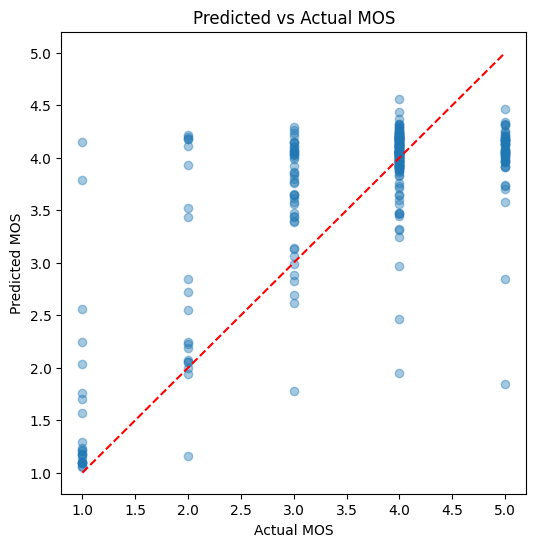

In [21]:
# Predicted vs actual MOS
title = "Predicted vs Actual MOS"
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.4)

# diagonal reference line (perfect prediction)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')

plt.xlabel("Actual MOS")
plt.ylabel("Predicted MOS")
plt.title(title)
plt.show()

# Save model

## On Google Colab

In [22]:
mount_point = '/content/drive'
drive.mount(mount_point, force_remount=True)
drive_path = mount_point + '/My Drive/'

Mounted at /content/drive


In [23]:
save_path = drive_path + 'Colab Notebooks/TSP - Data Science/Project/Models/'

In [24]:
%cd $save_path
!ls

/content/drive/My Drive/Colab Notebooks/TSP - Data Science/Project/Models


In [26]:
filename = save_path + f'RF.pkl'
pickle.dump(best_model, open(filename, 'wb'))

Optional: create a function to reduce duplication

In [ ]:
def search_or_load(model_filename, search, X_train, y_train):
  if (isfile(model_filename)):
    print("Loading model")
    model = pickle.load(open(model_filename, 'rb'))

  else:
    print("Searching the best hyper_parameters")
    search.fit(X_train, y_train)
    print(search.best_params_)
    model = search.best_estimator_
    print("Training model")
    model.fit(X_train,y_train)
    pickle.dump(model, open(model_filename, 'wb'))
    print("Model saved in in file ", model_filename)
  return model

## On Linux

In [ ]:
from pathlib import Path
from datetime import datetime

model_tag = "RF"

model_artifact = f'{model_tag}.pkl'

# Timestamp for this run, to avoid overwriting previous runs
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Always under home, in a dedicated results folder
SAVE_PATH = Path.home() / "ds_result" / timestamp

FINAL_MODEL_PATH = str(SAVE_PATH / model_artifact)

print("Final model path:", FINAL_MODEL_PATH)